# 07 · Robust coupled detectors on simulated slices: the real gain of coupling

**Question.** Notebook 04 predicted, to first order, that a coupled detector on latency gains about 2× in information for faults concentrated in one slice, and almost nothing for shared faults. That assumed the detector knows the fault's shape. Here we measure the **realised** gain at a common ARL, for detectors that do **not** know the shape.

**Detectors.** All watch the same three streams: each slice's latency, AR(1)-whitened with a fault-free stream model, the KPI where notebook 03 found the coupling.

| detector | knows the fault shape? | how it combines slices |
|---|---|---|
| per-slice CUSUM | no | one CUSUM per slice ($k = 0.5$), alarm on the maximum (equalised thresholds), the notebook-05 approach |
| CUSUM bank | no | 20 coupled CUSUMs, one per candidate shape. The candidates are each slice alone, all three together, each pair together and each pair opposite, all with both signs. Each is the matched filter $z^\top\Sigma^{-1}d$ (`CUSUMBank`), and the alarm goes to the first to cross its (equalised) threshold |
| MEWMA | no | multivariate EWMA with Hotelling $T^2$, fully direction-free |
| oracle coupled CUSUM | **yes** | one coupled CUSUM in the fault's true direction, measured separately; an upper bound, not a usable detector |

All four are calibrated by simulation to ARL 1000 windows (100 s), then run on the notebook-05 sweep with the same seeds. The URLLC loss burst is skipped, since latency does not move under it. **Realised gain** = (per-slice delay) / (coupled delay).

**Run it** from the project root (about 7 minutes):

```
.venv\Scripts\python -m nbconvert --to notebook --execute --inplace notebooks/07_coupled_detectors.ipynb
```

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from slicead.sim import Fault, load_config, load_fault_scenarios, simulate
from slicead.detectors import CUSUM, CUSUMBank, MEWMA, StreamModel, candidate_directions, stream_array
from slicead.eval import calibrate_bank, calibrate_per_stream, calibrate_threshold, first_alarms, summarize_delays

SEED = 20261022                      # same seeds as notebooks 05 and 06
OUT = Path("../results/07_coupled_detectors")
OUT.mkdir(parents=True, exist_ok=True)
REPORT = Path("../report")
for sub in ("figures", "tables"):                      # report/ is not in the public repository
    (REPORT / sub).mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    fig.savefig(REPORT / "figures" / f"07_{name}.pdf", bbox_inches="tight")

def save_tex_table(df, name, column_format):
    (REPORT / "tables" / f"07_{name}.tex").write_text(
        df.to_latex(index=False, escape=False, column_format=column_format), encoding="utf-8")

def save_tex_numbers(numbers, name="numbers"):
    lines = [f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in numbers.items()]
    (REPORT / "tables" / f"07_{name}.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "lines.markersize": 6, "font.size": 10,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150,
})

cfg = load_config("../configs/sim_default.yaml")
LAT = [("eMBB", "latency_ms"), ("URLLC", "latency_ms"), ("mMTC", "latency_ms")]
TARGET_ARL, CHANGE_S, HORIZON_W = 1000, 10.0, 300
STRENGTHS = [0.03, 0.1, 0.25, 0.5, 1.0]

## 1. Stream model, correlation and calibration

In [2]:
t0 = time.time()
train = simulate(cfg, n_windows=3000, n_runs=8, seed=SEED)
calib = simulate(cfg, n_windows=3000, n_runs=32, seed=SEED + 1)
model = StreamModel().fit(stream_array(train, LAT))
Ztrain = model.whiten(stream_array(train, LAT))
Sigma = np.corrcoef(Ztrain.reshape(-1, 3).T)
Zcal = model.whiten(stream_array(calib, LAT))
print(f"simulated in {time.time() - t0:.0f} s")
print("fault-free correlation of whitened latency residuals (eMBB, URLLC, mMTC):")
print(np.round(Sigma, 2))

per_slice = CUSUM(0.5)
c_per, _ = calibrate_per_stream(per_slice, Zcal, TARGET_ARL)
bank = CUSUMBank(candidate_directions(3), Sigma)
c_bank, _ = calibrate_bank(bank, Zcal, TARGET_ARL)
mewma = MEWMA(Sigma, lam=0.2)
c_mewma, _ = calibrate_threshold(mewma, Zcal, TARGET_ARL)
print(f"thresholds: per-slice factor {c_per:.2f}, bank factor {c_bank:.2f}, MEWMA {c_mewma:.2f}")
print("bank per-candidate thresholds range: %.1f - %.1f" % (bank.scale.min(), bank.scale.max()))

simulated in 70 s
fault-free correlation of whitened latency residuals (eMBB, URLLC, mMTC):
[[1.   0.42 0.5 ]
 [0.42 1.   0.72]
 [0.5  0.72 1.  ]]


thresholds: per-slice factor 0.91, bank factor 0.98, MEWMA 4.56
bank per-candidate thresholds range: 3.4 - 16.7


## 2. The oracle: each fault's true latency direction

For the oracle we need each fault's direction in whitened-latency space. We measure it as in notebook 04, but from separate runs (8 runs at full strength, new seeds), so the oracle is not tuned on the test data. The same direction is used at every strength. Since the faults act nonlinearly, this is a slight approximation for the weak ones. From the direction $\delta$ we also compute notebook 04's first-order gain, $\delta^\top\Sigma^{-1}\delta / \max_j \delta_j^2$, to compare with the realised gain.

In [3]:
SCENARIOS = load_fault_scenarios("../configs/faults.yaml", start_s=CHANGE_S)
NICE = {"capacity_drop": "capacity drop", "capacity_degradation": "capacity degradation",
        "embb_surge": "eMBB surge", "urllc_surge": "URLLC surge", "mmtc_storm": "mMTC storm",
        "urllc_loss_burst": "URLLC loss burst", "urllc_weight_misconfig": "URLLC weight misconfig."}
USE = [n for n in SCENARIOS if n != "urllc_loss_burst"]

def scaled(faults, s):
    return [Fault(f.kind, f.start_s, f.factor ** s, f.slice, f.ramp_s) for f in faults]

oracle, rows = {}, []
for k, scen in enumerate(USE):
    res = simulate(cfg, n_windows=400, n_runs=8, seed=SEED + 500 + k, faults=SCENARIOS[scen])
    Z = model.whiten(stream_array(res, LAT))
    ramp = max(f.ramp_s for f in SCENARIOS[scen])
    post = res.time_s >= CHANGE_S + min(ramp, 20.0) + 2.0
    d = Z[:, post].mean(axis=(0, 1)) - Z[:, ~res.labels].mean(axis=(0, 1))
    o = CUSUMBank([d], Sigma)
    c_o, _ = calibrate_threshold(o, Zcal, TARGET_ARL)
    oracle[scen] = (o, c_o)
    fo_gain = (d @ np.linalg.solve(Sigma, d)) / np.max(d**2)
    rows.append(dict(scenario=NICE[scen], d_eMBB=d[0], d_URLLC=d[1], d_mMTC=d[2], first_order_gain=fo_gain))
directions = pd.DataFrame(rows)
directions.round(2)

,scenario,d_eMBB,d_URLLC,d_mMTC,first_order_gain
0,capacity drop,0.62,1.51,1.33,1.06
1,capacity degradation,0.35,0.63,0.54,1.05
2,eMBB surge,0.24,0.08,0.06,1.08
3,URLLC surge,0.13,9.20,0.05,2.09
4,mMTC storm,0.33,0.09,9.41,2.24
5,URLLC weight misconfig.,0.06,18.08,-0.70,2.22


## 3. The sweep

In [4]:
N_RUNS, N_WINDOWS = 32, 400
ALL_NAMES = list(SCENARIOS)
rows = []
t0 = time.time()
for scen in USE:
    i = ALL_NAMES.index(scen)                       # same seeds as notebook 05
    for j, s in enumerate(STRENGTHS):
        res = simulate(cfg, n_windows=N_WINDOWS, n_runs=N_RUNS, seed=SEED + 100 + 10 * i + j,
                       faults=scaled(SCENARIOS[scen], s))
        Z = model.whiten(stream_array(res, LAT))
        for name, (det, c) in {"per-slice CUSUM": (per_slice, c_per), "CUSUM bank": (bank, c_bank),
                               "MEWMA": (mewma, c_mewma), "oracle coupled": oracle[scen]}.items():
            t_alarm, _ = first_alarms(det, Z, c)
            rows.append(dict(scenario=NICE[scen], strength=s, detector=name,
                             **summarize_delays(t_alarm, res.fault_window, HORIZON_W, res.window_s)))
sweep = pd.DataFrame(rows)
sweep.to_csv(OUT / "sweep.csv", index=False)
print(f"sweep simulated and scored in {time.time() - t0:.0f} s")
sweep.pivot_table(index=["scenario", "strength"], columns="detector", values="delay_mean_s").round(1)

sweep simulated and scored in 205 s


detector                          CUSUM bank  MEWMA  oracle coupled  \
scenario                strength                                      
URLLC surge             0.03            23.3   26.4            19.1   
                        0.10             3.3   13.3             2.0   
                        0.25             0.2    0.8             0.2   
                        0.50             0.1    0.1             0.1   
                        1.00             0.1    0.1             0.1   
URLLC weight misconfig. 0.03            16.9   25.5            13.9   
                        0.10             0.4    4.9             0.5   
                        0.25             0.1    0.2             0.1   
                        0.50             0.1    0.1             0.1   
                        1.00             0.1    0.1             0.1   
capacity degradation    0.03            28.1   28.8            27.2   
                        0.10            28.3   27.4            26.1   
                        0.25            25.4   24.8            25.0   
                        0.50            22.6   21.5            20.8   
                        1.00            19.3   17.1            15.3   
capacity drop           0.03            26.9   25.1            26.1   
                        0.10            21.9   23.8            23.0   
                        0.25            15.6   15.4            14.3   
                        0.50             5.6    4.8             3.2   
                        1.00             0.6    0.6             0.5   
eMBB surge              0.03            25.9   27.4            26.8   
                        0.10            24.9   24.5            24.7   
                        0.25            25.4   28.4            24.0   
                        0.50            26.2   23.7            17.1   
                        1.00            18.1   22.3            13.8   
mMTC storm              0.03            23.7   24.6            20.4   
                        0.10             2.9   20.7             2.4   
                        0.25             0.1    1.2             0.1   
                        0.50             0.1    0.1             0.1   
                        1.00             0.1    0.1             0.1   

detector                          per-slice CUSUM  
scenario                strength                   
URLLC surge             0.03                 26.9  
                        0.10                 11.6  
                        0.25                  1.4  
                        0.50                  0.2  
                        1.00                  0.1  
URLLC weight misconfig. 0.03                 26.2  
                        0.10                  7.5  
                        0.25                  0.6  
                        0.50                  0.1  
                        1.00                  0.1  
capacity degradation    0.03                 27.0  
                        0.10                 27.1  
                        0.25                 24.9  
                        0.50                 22.3  
                        1.00                 18.6  
capacity drop           0.03                 28.2  
                        0.10                 24.2  
                        0.25                 15.9  
                        0.50                  4.0  
                        1.00                  0.6  
eMBB surge              0.03                 25.5  
                        0.10                 23.4  
                        0.25                 26.4  
                        0.50                 21.6  
                        1.00                 16.4  
mMTC storm              0.03                 24.5  
                        0.10                 13.9  
                        0.25                  1.7  
                        0.50                  0.2  
                        1.00                  0.1

C:\Users\Asus\AppData\Local\Temp\ipykernel_23212\599734741.py:7: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(d.strength, d.delay_mean_s, "o-", color=col, label=det, mec=SURFACE, mew=1,


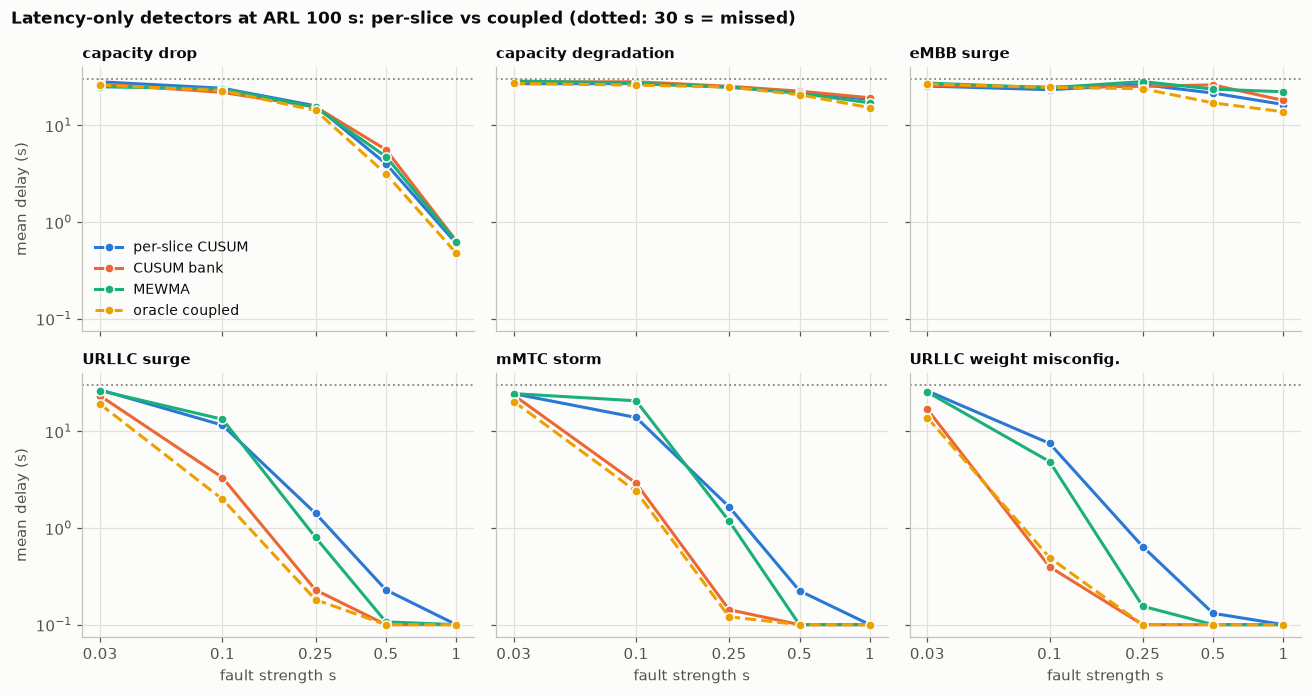

In [5]:
DETS = ["per-slice CUSUM", "CUSUM bank", "MEWMA", "oracle coupled"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.4), sharex=True, sharey=True)
for ax, scen in zip(axes.ravel(), [NICE[n] for n in USE]):
    g = sweep[sweep.scenario == scen]
    for col, det in zip(PALETTE, DETS):
        d = g[g.detector == det].sort_values("strength")
        ax.plot(d.strength, d.delay_mean_s, "o-", color=col, label=det, mec=SURFACE, mew=1,
                ls="--" if det == "oracle coupled" else "-")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.axhline(30, color=MUTED, ls=":", lw=1.2)
    ax.set_title(scen, fontsize=10)
for ax in axes[1]:
    ax.set_xticks(STRENGTHS, [f"{s:g}" for s in STRENGTHS]); ax.minorticks_off()
    ax.set_xlabel("fault strength s")
for ax in axes[:, 0]:
    ax.set_ylabel("mean delay (s)")
axes[0, 0].legend(loc="lower left", fontsize=9)
fig.suptitle("Latency-only detectors at ARL 100 s: per-slice vs coupled (dotted: 30 s = missed)",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig1_delay_coupled")
plt.show()

## 4. Realised gain of coupling

Realised gain = per-slice delay ÷ coupled delay, at strengths where the per-slice CUSUM detects at least 90% of runs, so that the ratio of means is not a ratio of censored horizons. It is compared with the first-order gain from section 2.

In [6]:
piv = sweep.pivot_table(index=["scenario", "strength"], columns="detector", values="delay_mean_s")
det_ok = sweep[sweep.detector == "per-slice CUSUM"].set_index(["scenario", "strength"]).detected >= 0.9
G = pd.DataFrame({f"gain {d}": piv["per-slice CUSUM"] / piv[d] for d in ["CUSUM bank", "MEWMA", "oracle coupled"]})
G = G[det_ok.reindex(G.index).fillna(False)]
G = G.join(directions.set_index("scenario").first_order_gain, on="scenario")
G.to_csv(OUT / "gains.csv")
G.round(2)

gain CUSUM bank  gain MEWMA  \
scenario                strength                                
URLLC surge             0.25                 6.20        1.77   
                        0.50                 2.29        2.14   
                        1.00                 1.00        1.00   
URLLC weight misconfig. 0.10                18.93        1.54   
                        0.25                 6.43        4.14   
                        0.50                 1.31        1.31   
                        1.00                 1.00        1.00   
capacity degradation    1.00                 0.96        1.08   
capacity drop           0.25                 1.02        1.04   
                        0.50                 0.72        0.84   
                        1.00                 0.94        0.96   
mMTC storm              0.25                11.60        1.40   
                        0.50                 2.24        2.24   
                        1.00                 1.00        1.00   

                                  gain oracle coupled  first_order_gain  
scenario                strength                                         
URLLC surge             0.25                     7.81              2.09  
                        0.50                     2.29              2.09  
                        1.00                     1.00              2.09  
URLLC weight misconfig. 0.10                    15.20              2.22  
                        0.25                     6.43              2.22  
                        0.50                     1.31              2.22  
                        1.00                     1.00              2.22  
capacity degradation    1.00                     1.22              1.05  
capacity drop           0.25                     1.12              1.06  
                        0.50                     1.27              1.06  
                        1.00                     1.26              1.06  
mMTC storm              0.25                    13.73              2.24  
                        0.50                     2.24              2.24  
                        1.00                     1.00              2.24

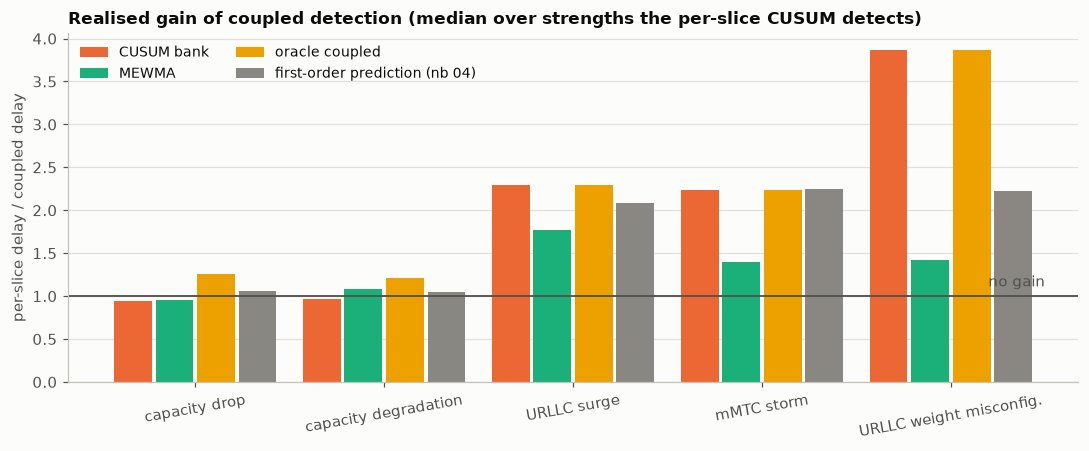

,gain CUSUM bank,gain MEWMA,gain oracle coupled,first_order_gain
scenario,,,,
capacity drop,0.94,0.96,1.26,1.06
capacity degradation,0.96,1.08,1.22,1.05
URLLC surge,2.29,1.77,2.29,2.09
mMTC storm,2.24,1.40,2.24,2.24
URLLC weight misconfig.,3.87,1.43,3.87,2.22


In [7]:
fig, ax = plt.subplots(figsize=(10, 4.2))
summary = G.groupby("scenario").agg(["median"]).droplevel(1, axis=1)
summary = summary.reindex([NICE[n] for n in USE]).dropna(how="all")
x = np.arange(len(summary))
w = 0.2
for k, (colname, col) in enumerate([("gain CUSUM bank", PALETTE[1]), ("gain MEWMA", PALETTE[2]),
                                     ("gain oracle coupled", PALETTE[3]), ("first_order_gain", MUTED)]):
    ax.bar(x + (k - 1.5) * (w + 0.02), summary[colname], width=w, color=col,
           label={"first_order_gain": "first-order prediction (nb 04)"}.get(colname, colname.replace("gain ", "")))
ax.axhline(1, color=INK2, lw=1.2)
ax.annotate("no gain", (len(summary) - 0.5, 1), xytext=(0, 4), textcoords="offset points", ha="right",
            va="bottom", color=INK2)
ax.set_xticks(x, summary.index, rotation=10)
ax.grid(axis="x", visible=False)
ax.set_ylabel("per-slice delay / coupled delay")
ax.set_title("Realised gain of coupled detection (median over strengths the per-slice CUSUM detects)")
ax.legend(loc="upper left", ncol=2, fontsize=9)
fig.tight_layout()
save_fig(fig, "fig2_realised_gain")
plt.show()
summary.round(2)

**What the sweep shows**

- **For faults concentrated in one slice, the shape-agnostic bank gains far more than first-order theory predicted.**
  - At strengths small enough not to be trivial, it is 6.2× faster on the URLLC surge ($s = 0.25$: 0.2 s against 1.4 s), 11.6× on the mMTC storm ($s = 0.25$) and 19× on the weight misconfiguration ($s = 0.1$: 0.4 s against 7.5 s).
  - Notebook 04's first-order prediction was about 2.1–2.2×.
  - The medians in the figure are lower because they include the strongest faults, where both detectors alarm in the first window (gain 1).
- **Why more than theory:** the excess comes from the structure of the fault-free noise, not from the fault. Notebook 09 tested the first explanation, cancellation of heavy common-mode tails, and **refuted it**. The real mechanism is cancellation of *slow, low-frequency* common-mode noise (eMBB bursts, capacity drift): the gain is governed by the cross-slice coherence at frequency zero, not by the instantaneous correlation.
- **The bank loses nothing to the oracle on local faults.** Its "one slice alone" candidates already match their directions, so not knowing the fault shape costs nothing here.
- **Shared faults: no gain, as predicted.** The bank is at 0.94–0.96 of per-slice CUSUM on the capacity faults; only the oracle, which knows the exact shared direction, gains 1.2–1.3×.
- **MEWMA is the weakest coupled detector on local faults** (1.4–1.8×). Being direction-free, it spreads its sensitivity over all directions.

**How this compares with the full 11-KPI detector of notebook 05** (same seeds, so the same simulated runs):
- **Traffic surges:** the latency bank is *slower* than per-stream CUSUM on all 11 KPIs, because surges show directly in throughput. URLLC surge at $s = 0.1$: 3.3 s against 0.4 s.
- **The weight misconfiguration changes no traffic, only delay.** The latency bank catches it at $s = 0.1$ in 0.4 s, against 4.1 s for the best all-KPI detector: about **10× faster**. Coupled detection pays off exactly for faults that are visible only in delay.

In [8]:
# Export tables and key numbers for report/main.tex
rows = []
for scen in [NICE[n] for n in USE]:
    for s in STRENGTHS:
        r = {"fault": scen, "$s$": f"{s:g}"}
        for d in DETS:
            g = sweep[(sweep.scenario == scen) & (sweep.strength == s) & (sweep.detector == d)].iloc[0]
            r[d] = f"{g.delay_mean_s:.1f}" if g.detected >= 0.995 else f"{g.delay_mean_s:.1f} ({100 * g.detected:.0f}\\%)"
        rows.append(r)
tab = pd.DataFrame(rows)
tab["fault"] = [f if i == 0 or f != tab.fault[i - 1] else "" for i, f in enumerate(tab.fault)]
save_tex_table(tab, "sweep", "llrrrr")

st = summary.reset_index()
st = st.assign(**{c: st[c].map(lambda v: "--" if pd.isna(v) else f"{v:.2f}") for c in st.columns if c != "scenario"})
st.columns = ["fault", "bank", "MEWMA", "oracle", "first order"]
save_tex_table(st, "gains", "lrrrr")

S = summary
mean_delay = sweep.groupby("detector").delay_mean_s.mean()
save_tex_numbers({
    "CplSigmaEU": f"{Sigma[0, 1]:.2f}", "CplSigmaUM": f"{Sigma[1, 2]:.2f}", "CplSigmaEM": f"{Sigma[0, 2]:.2f}",
    "CplBankCap": f"{S.loc['capacity drop', 'gain CUSUM bank']:.2f}",
    "CplOracleCap": f"{S.loc['capacity drop', 'gain oracle coupled']:.2f}",
    "CplMewmaCap": f"{S.loc['capacity drop', 'gain MEWMA']:.2f}",
    "CplBankUrllc": f"{S.loc['URLLC surge', 'gain CUSUM bank']:.2f}",
    "CplOracleUrllc": f"{S.loc['URLLC surge', 'gain oracle coupled']:.2f}",
    "CplFoUrllc": f"{S.loc['URLLC surge', 'first_order_gain']:.2f}",
    "CplMeanPer": f"{mean_delay['per-slice CUSUM']:.1f}", "CplMeanBank": f"{mean_delay['CUSUM bank']:.1f}",
    "CplMeanMewma": f"{mean_delay['MEWMA']:.1f}", "CplMeanOracle": f"{mean_delay['oracle coupled']:.1f}",
})
print("exported:", sorted(p.name for p in (REPORT / "tables").glob("07_*")))

exported: ['07_gains.tex', '07_numbers.tex', '07_sweep.tex']


## 5. Summary

- **A shape-agnostic bank of coupled CUSUMs (20 candidate directions) is a practical coupled detector.** It matches the oracle on faults concentrated in one slice.
- **On latency, coupling gives realised gains of 6–19× for small slice-local faults, far above the first-order 2×.** The reason, tested in notebook 09, is that the slices share slow, low-frequency noise: cancelling it across slices removes most of what a CUSUM accumulates (not heavy tails, as first thought).
- **Coupling does not help shared faults** (bank about 0.95×).
- **Compared with the best detector on all 11 KPIs,** the coupled latency bank is slower for traffic surges (visible in throughput) but about 10× faster for the weight misconfiguration, a fault that changes no traffic.
- **The natural next step** is to combine the 11-KPI per-stream CUSUM and the latency bank in one jointly calibrated detector, to get the best of both.